<a href="https://colab.research.google.com/github/anandhari911/employee_performances/blob/main/employee_performance.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
sns.set_theme(style='whitegrid')

In [ ]:
file1='/content/IT_Organization_Employee_Performance_Analysis_Data.xlsx'
file2='/content/Employee Data.xlsx'

In [ ]:
emp_master=pd.read_excel(file1,sheet_name='Employee_Master')
quartly_performance=pd.read_excel(file1,sheet_name='Quarterly_Performance')
emp_data=pd.read_excel(file2,sheet_name='Sheet1')

In [ ]:
merged_perf=pd.merge(emp_master,quartly_performance,on='Employee_ID')

In [ ]:
dept_role_summary=merged_perf.groupby(['Department','Job_Title']).agg(
    Avg_Task_Completion=('Task_Completion_Rate_%','mean'),
    Avg_On_Rate=('On_Time_Rate_%','mean'),
    Avg_Defects=('Production_Defects','mean'),
    Avg_Manager_Rating=('Manager_Rating_1_5','mean'),
).round(2).reset_index()
print(dept_role_summary)

          Department                 Job_Title  Avg_Task_Completion  \
0      Cybersecurity               SOC Analyst                88.29   
1      Cybersecurity          Security Analyst                89.14   
2      Cybersecurity         Security Engineer                93.52   
3   Data & Analytics              Data Analyst                88.68   
4   Data & Analytics             Data Engineer                92.72   
5   Data & Analytics            Data Scientist                83.09   
6        Engineering           DevOps Engineer                84.44   
7        Engineering               QA Engineer                90.40   
8        Engineering                   QA Lead                91.55   
9        Engineering  Senior Software Engineer                91.68   
10       Engineering         Software Engineer                89.20   
11       Engineering                 Tech Lead                87.87   
12     IT Operations       IT Support Engineer                91.24   
13    

In [ ]:
print(dept_role_summary.sort_values(by='Avg_Task_Completion',ascending=False).head(10))

          Department                 Job_Title  Avg_Task_Completion  \
2      Cybersecurity         Security Engineer                93.52   
4   Data & Analytics             Data Engineer                92.72   
9        Engineering  Senior Software Engineer                91.68   
8        Engineering                   QA Lead                91.55   
12     IT Operations       IT Support Engineer                91.24   
16           Product           Product Analyst                90.42   
7        Engineering               QA Engineer                90.40   
13     IT Operations          Network Engineer                90.06   
17           Product           Product Manager                90.02   
15           Product          Business Analyst                89.27   

    Avg_On_Rate  Avg_Defects  Avg_Manager_Rating  
2         85.81         1.88                3.82  
4         86.52         3.03                3.80  
9         87.05         2.12                4.25  
8         86.7

In [ ]:

quarterly_trends=merged_perf.groupby('Quarter').agg(
    Avg_Task_Completion=('Task_Completion_Rate_%','mean'),
    Avg_On_Rate=('On_Time_Rate_%','mean'),
    Avg_Goal_Achievements=('Goal_Achievement_Rate_%','mean'),
    Avg_Defects=('Production_Defects','mean'),
    Avg_Manager_Rating=('Manager_Rating_1_5','mean'),
).round(2).reset_index()
print(quarterly_trends)

  Quarter  Avg_Task_Completion  Avg_On_Rate  Avg_Goal_Achievements  \
0      Q1                90.67        86.65                  76.54   
1      Q2                88.84        85.80                  79.66   
2      Q3                90.52        86.98                  75.81   
3      Q4                87.87        85.76                  78.60   

   Avg_Defects  Avg_Manager_Rating  
0         2.58                3.88  
1         2.99                3.96  
2         2.69                3.81  
3         2.49                3.96  


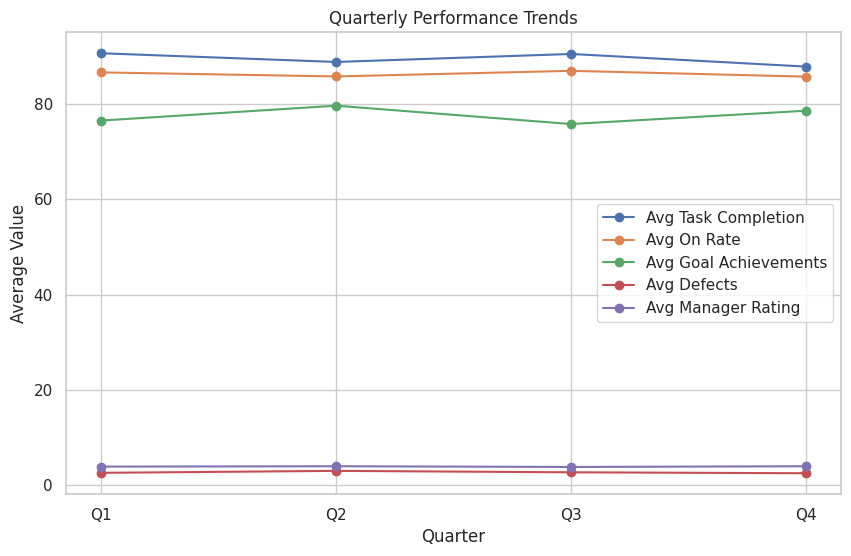

In [ ]:
plt.figure(figsize=(10,6))
plt.plot(quarterly_trends['Quarter'],quarterly_trends['Avg_Task_Completion'],marker='o',label='Avg Task Completion')
plt.plot(quarterly_trends['Quarter'],quarterly_trends['Avg_On_Rate'],marker='o',label='Avg On Rate')
plt.plot(quarterly_trends['Quarter'],quarterly_trends['Avg_Goal_Achievements'],marker='o',label='Avg Goal Achievements')
plt.plot(quarterly_trends['Quarter'],quarterly_trends['Avg_Defects'],marker='o',label='Avg Defects')
plt.plot(quarterly_trends['Quarter'],quarterly_trends['Avg_Manager_Rating'],marker='o',label='Avg Manager Rating')
plt.xlabel('Quarter')
plt.ylabel('Average Value')
plt.title('Quarterly Performance Trends')
plt.legend()
plt.show()

In [ ]:
goal_summary=merged_perf.groupby('Department').agg(
    Total_Goal_Set=('Goals_Set','sum'),
    Total_Goal_Achieved=('Goals_Achieved','sum'),
    Goal_Achievement_Rate=('Goal_Achievement_Rate_%','mean'),
).round(2).reset_index()
print(goal_summary)

         Department  Total_Goal_Set  Total_Goal_Achieved  \
0     Cybersecurity             320                  261   
1  Data & Analytics             278                  225   
2       Engineering             475                  369   
3     IT Operations             479                  374   
4           Product             463                  372   

   Goal_Achievement_Rate  
0                  79.75  
1                  80.31  
2                  75.32  
3                  76.17  
4                  78.49  


In [ ]:
delievery_quality_cols=[
    "Task_Completion_Rate_%",
    "On_Time_Rate_%",
    "Production_Defects",
    "Reopened_Items",
    "Stakeholder_Satisfaction_1_5"
]
delievery_quality_corr=merged_perf[delievery_quality_cols].corr()
print(delievery_quality_corr)

                              Task_Completion_Rate_%  On_Time_Rate_%  \
Task_Completion_Rate_%                      1.000000       -0.056268   
On_Time_Rate_%                             -0.056268        1.000000   
Production_Defects                          0.183984       -0.091612   
Reopened_Items                              0.078637       -0.052591   
Stakeholder_Satisfaction_1_5                0.058568        0.007112   

                              Production_Defects  Reopened_Items  \
Task_Completion_Rate_%                  0.183984        0.078637   
On_Time_Rate_%                         -0.091612       -0.052591   
Production_Defects                      1.000000        0.639561   
Reopened_Items                          0.639561        1.000000   
Stakeholder_Satisfaction_1_5            0.034342        0.030146   

                              Stakeholder_Satisfaction_1_5  
Task_Completion_Rate_%                            0.058568  
On_Time_Rate_%                      

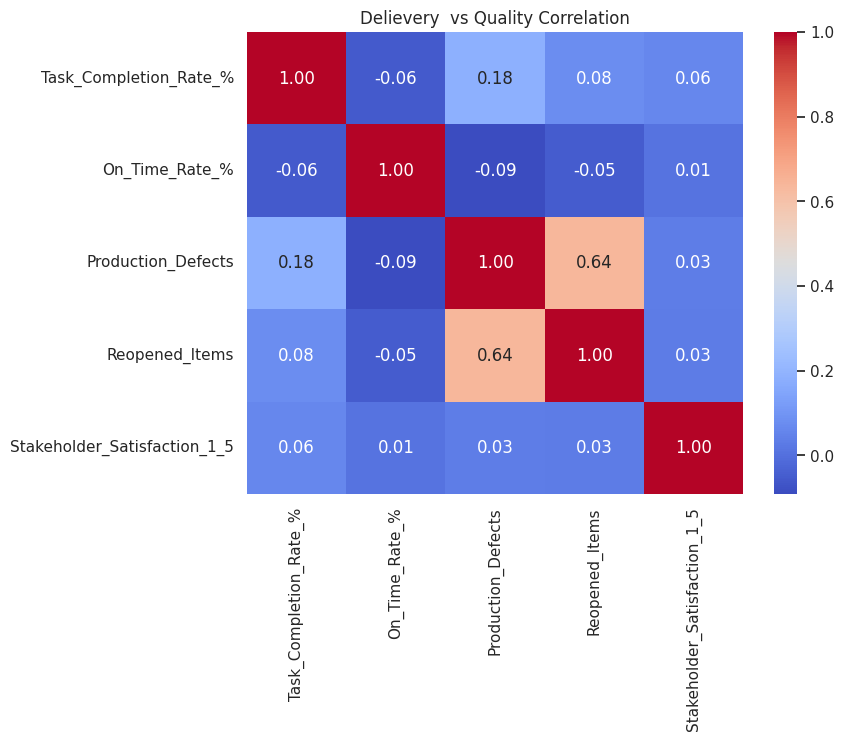

In [ ]:
plt.figure(figsize=(8,6))
sns.heatmap(delievery_quality_corr,annot=True,cmap='coolwarm',fmt='.2f')
plt.title('Delievery  vs Quality Correlation')
plt.show()

In [ ]:
high_defects=merged_perf[merged_perf['Production_Defects']>=6][
    ['Employee_ID','Employee_Name','Department','Quarter','Production_Defects','Manager_Rating_1_5']
]

In [ ]:
low_completion=merged_perf[merged_perf['Task_Completion_Rate_%']<75][
    ['Employee_ID','Employee_Name','Department','Quarter','Task_Completion_Rate_%','Manager_Rating_1_5']
]

In [ ]:
print(len(high_defects))
print(len(low_completion))

26
20


In [ ]:
manager_dashboard=merged_perf.groupby(["Manager_ID","Department"]).agg(
    Direct_Reports=('Employee_ID','nunique'),
    Avg_Task_Completion=('Task_Completion_Rate_%','mean'),
    Avg_On_Rate=('On_Time_Rate_%','mean'),
    Avg_Goal_Achievements=('Goal_Achievement_Rate_%','mean'),
    Avg_Defects=('Production_Defects','mean'),
    Avg_Manager_Rating=('Manager_Rating_1_5','mean'),
).round(2).reset_index().sort_values(by='Avg_Task_Completion',ascending=False)
print(manager_dashboard.head(10))

   Manager_ID        Department  Direct_Reports  Avg_Task_Completion  \
35     MGR011     IT Operations               1                96.20   
42     MGR013       Engineering               1                95.50   
20     MGR007  Data & Analytics               2                95.49   
25     MGR008       Engineering               2                95.48   
31     MGR010     IT Operations               2                95.35   
49     MGR014           Product               2                94.49   
15     MGR005  Data & Analytics               3                94.05   
10     MGR003           Product               1                93.98   
41     MGR013     Cybersecurity               1                93.75   
8      MGR003     Cybersecurity               1                93.40   

    Avg_On_Rate  Avg_Goal_Achievements  Avg_Defects  Avg_Manager_Rating  
35        84.65                  80.35         4.25                4.20  
42        81.00                  66.68         2.50        

In [ ]:
print("\n"+"="*60)
print(
    "Report generated successfully. Output plots saved as 'quarterly_trends_chart.png' and 'delivery_vs_quality_heatmap.png'."
)
print("=" * 60)


Report generated successfully. Output plots saved as 'quarterly_trends_chart.png' and 'delivery_vs_quality_heatmap.png'.


In [ ]:
X=pd.get_dummies(merged_perf.drop(['Employee_ID','Employee_Name','Department','Quarter','Joining_Date'],axis=1))
y=merged_perf['Task_Completion_Rate_%']

In [ ]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)

In [ ]:
from sklearn.linear_model import LinearRegression
lr=LinearRegression()
lr.fit(X_train,y_train)

LinearRegression()

In [ ]:
y_pred=lr.predict(X_test)

In [ ]:
y_pred

array([100. ,  87.5, 100. ,  82.8,  76. , 100. , 100. , 100. ,  87.9,
        92.9,  92. ,  76.5,  95.1,  78.9,  75. ,  90. , 100. ,  81.8,
        87.5,  91.7,  97.3,  83.7,  89.5,  88.2,  73.8,  85. , 100. ,
        97.7,  78.9,  87.2,  80. , 100. , 100. ,  78.9, 100. ,  93.3,
        94.6,  94.1,  96.8,  74.2,  97.2,  91.2,  85.4,  72.7, 100. ,
        77.8,  77.8,  93.3, 100. , 100. ,  90.5,  77.3,  82.9,  94.9,
        85.3,  94.4,  85. ,  86.4,  94.6,  80.5,  88.5,  82.6, 100. ,
        95.5, 100. ,  77.8,  75.8, 100. ,  94.7,  91.2,  80. , 100. ,
       100. ,  77.3, 100. ,  84.6,  86.8,  97.7,  84.8,  77.8])

In [ ]:
from sklearn.metrics import mean_squared_error,r2_score
mse=mean_squared_error(y_test,y_pred)
r2=r2_score(y_test,y_pred)

In [ ]:
mse

7.040425806916486e-27

In [ ]:
r2

1.0

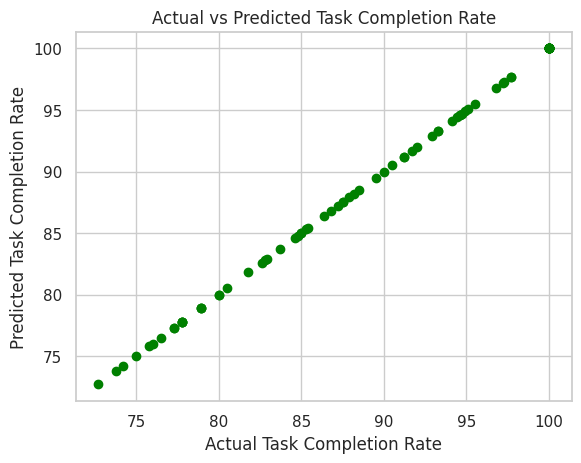

In [ ]:
plt.scatter(y_test,y_pred,color='green')
plt.xlabel('Actual Task Completion Rate')
plt.ylabel('Predicted Task Completion Rate')
plt.title('Actual vs Predicted Task Completion Rate')
plt.show()

In [ ]:
from sklearn.ensemble import RandomForestRegressor
rf=RandomForestRegressor(n_estimators=100,random_state=42)
rf.fit(X_train,y_train)

RandomForestRegressor(random_state=42)

In [ ]:
y_pred_rf=rf.predict(X_test)

In [ ]:
y_pred_rf

array([100.   ,  87.445, 100.   ,  82.806,  75.974, 100.   , 100.   ,
       100.   ,  87.951,  93.015,  92.015,  76.185,  95.085,  78.972,
        75.014,  89.859, 100.   ,  81.726,  87.47 ,  91.926,  97.184,
        83.871,  89.566,  87.997,  73.972,  84.983, 100.   ,  97.592,
        78.96 ,  87.061,  79.926, 100.   , 100.   ,  78.893, 100.   ,
        93.32 ,  94.559,  94.014,  96.733,  74.134,  97.158,  91.124,
        85.322,  73.076, 100.   ,  77.91 ,  77.939,  93.376, 100.   ,
       100.   ,  90.522,  77.294,  82.828,  95.027,  85.287,  94.283,
        84.972,  86.498,  94.519,  80.628,  88.388,  82.557, 100.   ,
        95.579, 100.   ,  77.938,  75.915, 100.   ,  94.507,  91.157,
        79.986, 100.   , 100.   ,  77.34 , 100.   ,  84.554,  86.769,
        97.564,  84.806,  77.832])

In [ ]:
mean_squared_error(y_test,y_pred_rf)

0.009452112500000531

In [ ]:
r2_score(y_test,y_pred_rf)

0.9998744380839657

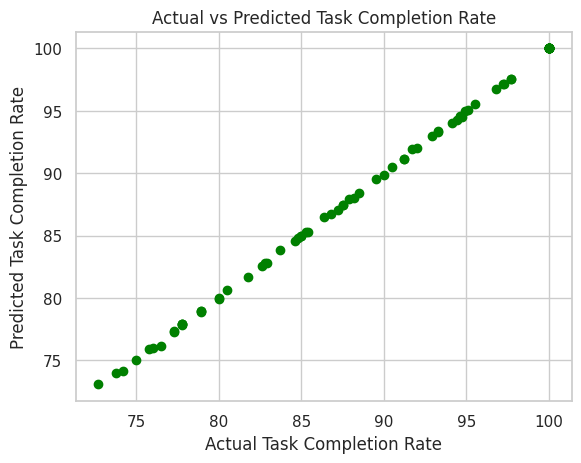

In [ ]:
plt.scatter(y_test,y_pred_rf,color='green')
plt.xlabel('Actual Task Completion Rate')
plt.ylabel('Predicted Task Completion Rate')
plt.title('Actual vs Predicted Task Completion Rate')
plt.show()

In [ ]:
merged_perf

,Employee_ID,Employee_Name,Department,Job_Title,Level,Experience_Years,Location,Employment_Type,Manager_ID,Joining_Date,...,Training_Hours,Goals_Set,Goals_Achieved,Peer_Feedback_Rating_1_5,Manager_Rating_1_5,Stakeholder_Satisfaction_1_5,Overtime_Hours,Task_Completion_Rate_%,On_Time_Rate_%,Goal_Achievement_Rate_%
0,EMP001,Kavya Rao,Engineering,Software Engineer,L2,11.3,Hyderabad,Full-time,MGR015,2024-03-25,...,12.7,3,3,4.1,3.3,3.5,19.3,73.8,80.6,100.0
1,EMP001,Kavya Rao,Engineering,Software Engineer,L2,11.3,Hyderabad,Full-time,MGR015,2024-03-25,...,16.2,4,3,4.9,3.4,4.5,14.5,85.7,76.7,75.0
2,EMP001,Kavya Rao,Engineering,Software Engineer,L2,11.3,Hyderabad,Full-time,MGR015,2024-03-25,...,13.2,4,2,3.4,4.5,3.9,32.7,100.0,78.8,50.0
3,EMP001,Kavya Rao,Engineering,Software Engineer,L2,11.3,Hyderabad,Full-time,MGR015,2024-03-25,...,16.5,4,3,4.0,3.5,4.2,19.0,82.4,71.4,75.0
4,EMP002,Aarav Reddy,Engineering,QA Lead,L2,6.6,Bengaluru,Full-time,MGR001,2024-08-02,...,20.8,6,4,3.5,3.8,4.8,13.3,100.0,96.9,66.7
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
395,EMP099,Arjun Iyer,Engineering,QA Engineer,L1,1.8,Chennai,Full-time,MGR014,2012-01-10,...,13.8,5,4,4.3,3.6,4.3,33.6,80.0,82.1,80.0
396,EMP100,Vihaan Das,Cybersecurity,Security Engineer,L3,6.5,Mumbai,Full-time,MGR011,2021-11-30,...,8.4,4,2,4.0,4.9,4.4,10.5,85.0,94.1,50.0
397,EMP100,Vihaan Das,Cybersecurity,Security Engineer,L3,6.5,Mumbai,Full-time,MGR011,2021-11-30,...,18.2,4,2,3.2,4.4,4.3,17.1,100.0,90.0,50.0
398,EMP100,Vihaan Das,Cybersecurity,Security Engineer,L3,6.5,Mumbai,Full-time,MGR011,2021-11-30,...,23.3,3,1,3.5,3.5,4.5,14.2,100.0,90.0,33.3


In [ ]:
merged_perf.describe()

,Experience_Years,Joining_Date,Year,Tasks_Assigned,Tasks_Completed,Tasks_Completed_On_Time,Production_Defects,Reopened_Items,Attendance_Percent,Training_Hours,Goals_Set,Goals_Achieved,Peer_Feedback_Rating_1_5,Manager_Rating_1_5,Stakeholder_Satisfaction_1_5,Overtime_Hours,Task_Completion_Rate_%,On_Time_Rate_%,Goal_Achievement_Rate_%
count,400.00000,400,400.0,400.00000,400.000000,400.000000,400.00000,400.000000,400.000000,400.000000,400.000000,400.000000,400.000000,400.000000,400.000000,400.000000,400.000000,400.000000,400.000000
mean,8.40100,2019-03-04 23:02:24,2026.0,31.10250,27.802500,23.980000,2.68750,0.537500,94.054750,12.527500,5.037500,4.002500,3.898000,3.902250,4.127750,17.606250,89.475750,86.297000,77.653000
min,0.60000,2012-01-10 00:00:00,2026.0,18.00000,14.000000,12.000000,0.00000,0.000000,88.100000,2.200000,3.000000,1.000000,2.800000,2.700000,3.200000,0.000000,72.700000,70.800000,33.300000
25%,4.60000,2016-04-24 18:00:00,2026.0,24.00000,21.000000,18.000000,1.00000,0.000000,91.200000,7.475000,4.000000,3.000000,3.300000,3.300000,3.700000,9.475000,82.100000,79.400000,66.700000
50%,8.30000,2019-04-21 00:00:00,2026.0,31.00000,28.000000,23.000000,3.00000,0.000000,94.150000,12.500000,5.000000,4.000000,3.900000,3.950000,4.200000,17.300000,90.500000,87.000000,80.000000
75%,12.10000,2022-03-21 12:00:00,2026.0,37.25000,34.000000,29.000000,4.00000,1.000000,97.225000,17.400000,6.000000,5.000000,4.400000,4.500000,4.500000,25.625000,100.000000,92.900000,100.000000
max,15.00000,2025-01-16 00:00:00,2026.0,45.00000,45.000000,42.000000,7.00000,3.000000,100.000000,23.900000,7.000000,7.000000,5.000000,5.000000,5.000000,35.000000,100.000000,100.000000,100.000000
std,4.28364,NaN,0.0,7.86904,7.513963,6.861289,1.62371,0.640014,3.418009,5.962493,1.343729,1.563203,0.624958,0.684208,0.510987,10.003104,8.914483,8.194744,19.582538


In [ ]:
merged_perf.isnull().sum()

,0
Employee_ID,0
Employee_Name,0
Department,0
Job_Title,0
Level,0
Experience_Years,0
Location,0
Employment_Type,0
Manager_ID,0
Joining_Date,0


In [ ]:
from sklearn.tree import DecisionTreeRegressor
dt=DecisionTreeRegressor(random_state=42)
dt.fit(X_train,y_train)

DecisionTreeRegressor(random_state=42)

In [ ]:
y_pred_dt=dt.predict(X_test)

In [ ]:
y_pred_dt

array([100. ,  87.2, 100. ,  82.9,  76. , 100. , 100. , 100. ,  87.9,
        92.9,  91.9,  76.3,  95.2,  79.3,  75. ,  90. , 100. ,  81.8,
        87.2,  91.7,  97.1,  83.7,  89.5,  88.2,  73.7,  85. , 100. ,
        97.7,  79.3,  87. ,  80. , 100. , 100. ,  78.8, 100. ,  93.3,
        94.6,  93.8,  96.7,  74.3,  97.1,  91.2,  85.4,  72.7, 100. ,
        77.8,  77.8,  93.3, 100. , 100. ,  90.5,  77.3,  82.9,  94.9,
        85.2,  94.4,  85. ,  86.4,  94.6,  80.6,  88.5,  82.6, 100. ,
        95.6, 100. ,  77.8,  75.9, 100. ,  95. ,  91.3,  80. , 100. ,
       100. ,  77.4, 100. ,  84.6,  86.5,  97.6,  84.6,  77.8])

In [ ]:
mean_squared_error(y_test,y_pred_dt)

0.013499999999999814

In [ ]:
r2_score(y_test,y_pred_dt)

0.9998206659234681

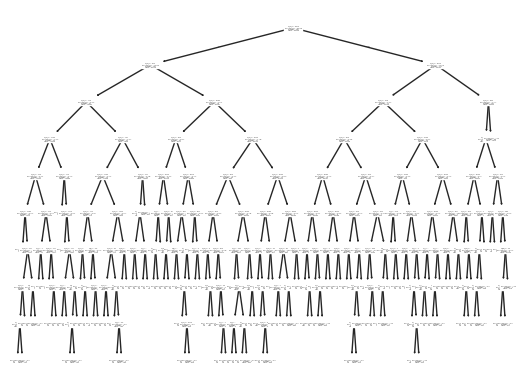

In [ ]:
from sklearn import tree
tree.plot_tree(dt)
plt.show()

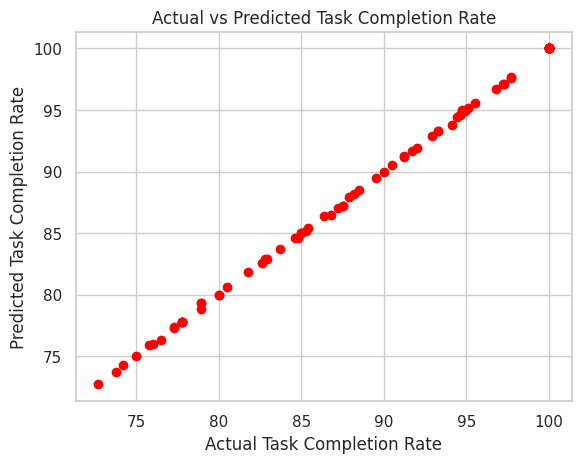

In [ ]:
plt.scatter(y_test,y_pred_dt,color='red')
plt.xlabel('Actual Task Completion Rate')
plt.ylabel('Predicted Task Completion Rate')
plt.title('Actual vs Predicted Task Completion Rate')
plt.show()

In [ ]:
from sklearn.ensemble import GradientBoostingRegressor
gb=GradientBoostingRegressor(n_estimators=100,random_state=42)
gb.fit(X_train,y_train)

GradientBoostingRegressor(random_state=42)

In [ ]:
y_pred_gb=gb.predict(X_test)

In [ ]:
y_pred_gb

array([100.00115574,  87.19011064,  99.99444679,  82.89050371,
        75.99172393,  99.99785215,  99.99111076,  99.99682946,
        87.86674063,  92.97860808,  91.88327593,  76.26551486,
        95.06194417,  78.78138943,  75.00798323,  90.01262814,
        99.99937917,  81.81301915,  87.20277748,  91.6437798 ,
        97.19228286,  83.66601401,  89.45622525,  88.12518937,
        73.90312581,  84.97941201,  99.99456415,  97.68023923,
        78.78182804,  87.21357205,  80.03078205,  99.99774149,
        99.99904367,  78.79631194,  99.99731041,  93.21350796,
        94.59203967,  93.90273312,  96.80548883,  74.23017788,
        97.20277846,  91.21258837,  85.51636344,  72.70976302,
        99.99989679,  77.79949582,  77.81755273,  93.22402998,
        99.99812775,  99.99462242,  90.49478205,  77.36392773,
        82.89811167,  94.90645318,  85.20750885,  94.41115228,
        84.96301831,  86.39606785,  94.58826628,  80.60348726,
        88.53365812,  82.60256447,  99.95621242,  95.49

In [ ]:
mean_squared_error(y_test,y_pred_gb)

0.005789738643776765

In [ ]:
r2_score(y_test,y_pred_gb)


0.9999230890790338

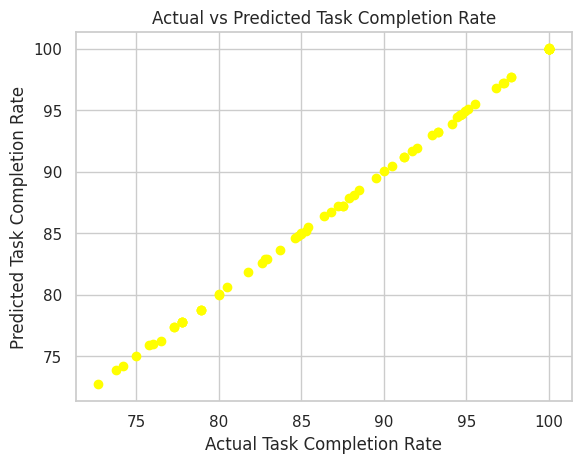

In [ ]:
plt.scatter(y_test,y_pred_gb,color='yellow')
plt.xlabel('Actual Task Completion Rate')
plt.ylabel('Predicted Task Completion Rate')
plt.title('Actual vs Predicted Task Completion Rate')
plt.show()